# Applied Statistics

Today we will learn how to use various distributions (Poisson, Gaussian), different types of averages (mean, median, mode), consider distribution widths and uncertainties, and perform a goodness of fit test.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## 1.  Distributions
To introduce this topic we will consider a practical example.  You are in London and want to get from Coram's Fields to King's Cross station.  You have two options: walk or take the Piccadilly line from Russel Square to King's Cross.  If you walk, you can expect it to take 14 minutes with an uncertainty of +/- 1 minute (standard deviation).  Model this as a Gaussian distribution and make a plot.  Tip: look at https://numpy.org/doc/2.3/reference/random/generated/numpy.random.normal.html with a large size to get a smooth distribution and make sure you add enough bins to the histogram

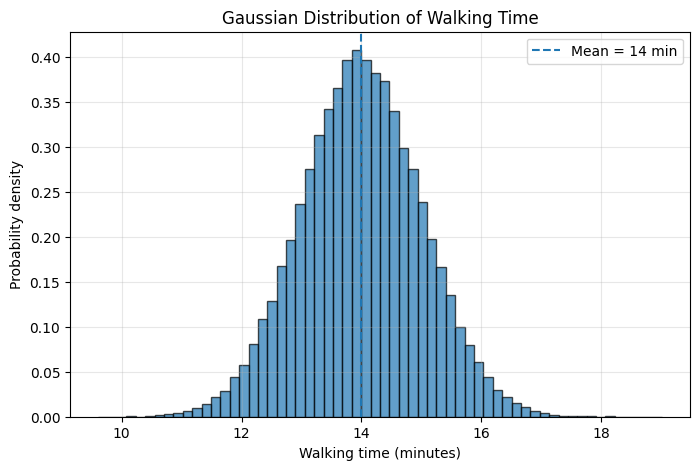

In [2]:
# Parameters of the Gaussian distribution
mean = 14       # mean walking time in minutes
std_dev = 1     # standard deviation in minutes

# Generate 100,000 random walking times
rng = np.random.default_rng(42)
walking_times = rng.normal(loc=mean, scale=std_dev, size=100000)

# Plot the histogram
plt.figure(figsize=(8, 5))
plt.hist(walking_times, bins=60, density=True, edgecolor='black', alpha=0.7)

plt.xlabel("Walking time (minutes)")
plt.ylabel("Probability density")
plt.title("Gaussian Distribution of Walking Time")
plt.axvline(mean, linestyle='--', label='Mean = 14 min')
plt.legend()
plt.grid(alpha=0.3)

plt.show()


You should see a smooth Gaussian distribution centered around 14.  Now, we want to model the tube option.  To do this we need to consider two parts: the time it will take to walk to the tube station (6 minutes, +/- 0.5 mins) and the time it will take for the tube.  The second part is a little more complicated as it has a larger high time tail to the distribution.  First make a plot of the time to walk to the tube station:

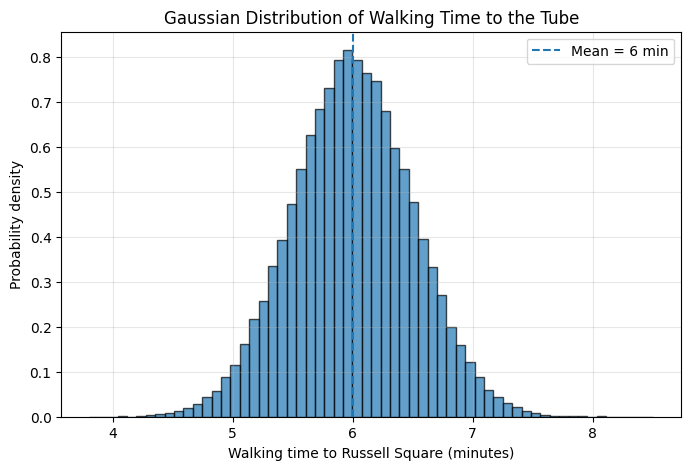

In [3]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters
mean = 6
std_dev = 0.5

# Generate random walking times
rng = np.random.default_rng(42)
walking_times = rng.normal(loc=mean, scale=std_dev, size=100000)

# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(walking_times, bins=60, density=True, edgecolor='black', alpha=0.7)

plt.xlabel("Walking time to Russell Square (minutes)")
plt.ylabel("Probability density")
plt.title("Gaussian Distribution of Walking Time to the Tube")
plt.axvline(mean, linestyle='--', label='Mean = 6 min')
plt.legend()
plt.grid(alpha=0.3)

plt.show()


Now you want to model the time to take the tube.  This can be modelled as a Gaussian distribution with peak of 6 mins and uncertainty 3 mins.  However, there is a lower cutoff to this time as the fastest it can be done is 5 mins.  Tip: when you plot a histogram it will return the values and bin edges as arrays you can then use.  Tip: you can use the 'weight' argument to plot a histogram where you have the bin content numbers.  Make a plot of this distribution:

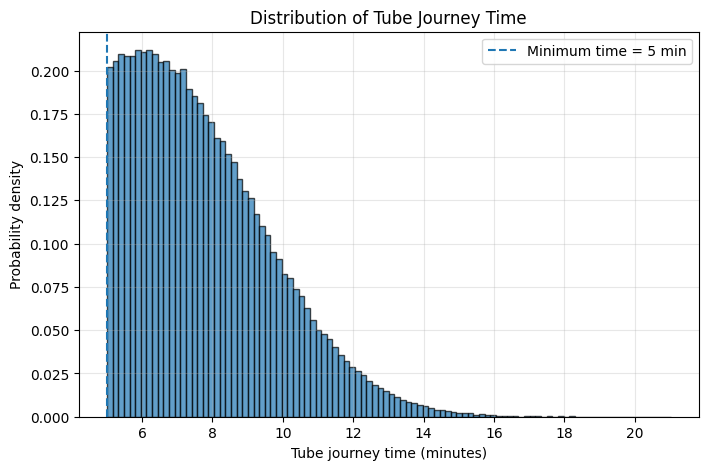

In [4]:

import numpy as np
import matplotlib.pyplot as plt

# Parameters
mean = 6
std_dev = 3
cutoff = 5

# Generate random tube times
rng = np.random.default_rng(42)
tube_times = rng.normal(loc=mean, scale=std_dev, size=500000)

# Apply the minimum time cutoff
tube_times = tube_times[tube_times >= cutoff]

# Plot histogram
plt.figure(figsize=(8, 5))
plt.hist(tube_times, bins=100, density=True, edgecolor='black', alpha=0.7)

plt.xlabel("Tube journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Distribution of Tube Journey Time")
plt.axvline(cutoff, linestyle='--', label='Minimum time = 5 min')
plt.legend()
plt.grid(alpha=0.3)

plt.show()


Now you probably have an array of bin values showing this distribution, but not the full distribution itself.  To get the distribution of tube times we can use https://numpy.org/doc/stable/reference/random/generated/numpy.random.choice.html (remember to scale your histogram values to make them probabilities)

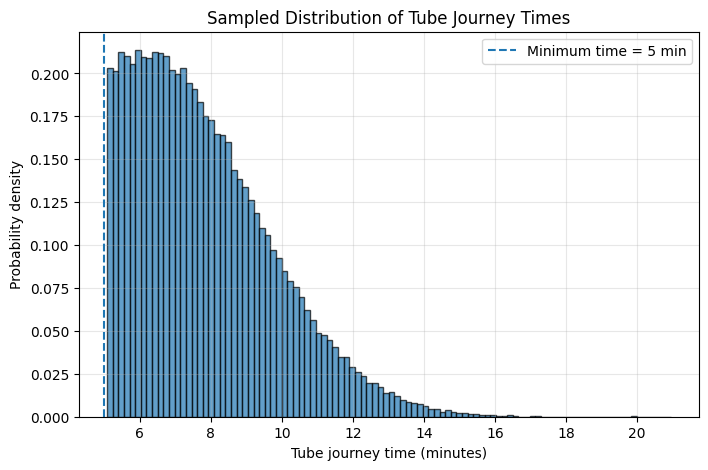

In [5]:

import numpy as np
import matplotlib.pyplot as plt

# Generate the tube-time distribution
rng = np.random.default_rng(42)

mean = 6
std_dev = 3
cutoff = 5

tube_times = rng.normal(loc=mean, scale=std_dev, size=500000)
tube_times = tube_times[tube_times >= cutoff]

# Calculate histogram values and bin edges
hist, bin_edges = np.histogram(tube_times, bins=100)

# Convert histogram counts into probabilities
probabilities = hist / hist.sum()

# Use the centre of each bin as its representative time
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2

# Randomly sample tube times from the distribution
sampled_tube_times = rng.choice(
    bin_centres,
    size=100000,
    p=probabilities
)

# Plot the resulting distribution
plt.figure(figsize=(8, 5))
plt.hist(sampled_tube_times, bins=100, density=True,
         edgecolor='black', alpha=0.7)

plt.xlabel("Tube journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Sampled Distribution of Tube Journey Times")
plt.axvline(5, linestyle='--', label='Minimum time = 5 min')
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Now you have your two distributions for the time it takes to walk to the tube station and the time it takes to take the tube.  Sum the two distributions to get a distribution for the total time it takes to take the tube from Coram's Fields to King's Cross.  Make a plot of this distribution:

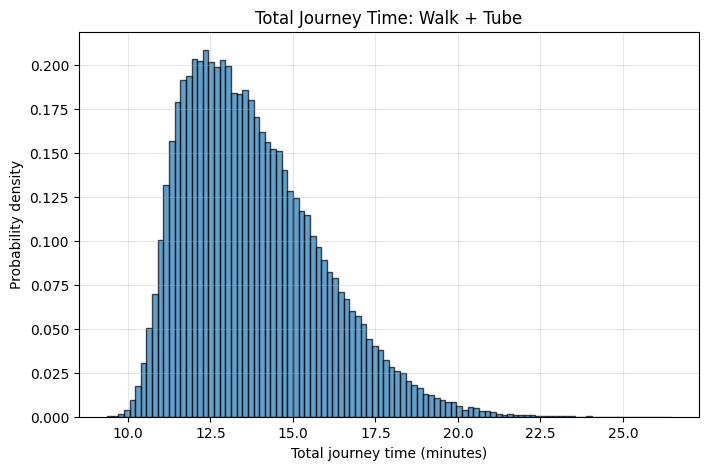

In [6]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

# 1. Walking time to Russell Square: Gaussian distribution
n = 100000
walk_times = rng.normal(loc=6, scale=0.5, size=n)

# 2. Tube journey time: Gaussian with minimum cutoff of 5 minutes
raw_tube_times = rng.normal(loc=6, scale=3, size=500000)
raw_tube_times = raw_tube_times[raw_tube_times >= 5]

# Create histogram and calculate probabilities
hist, bin_edges = np.histogram(raw_tube_times, bins=100)
probabilities = hist / hist.sum()

# Use bin centres to represent tube journey times
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2

# Sample tube times using the histogram probabilities
tube_times = rng.choice(
    bin_centres, size=n, p=probabilities
)

# 3. Add the two journey times sample by sample
total_times = walk_times + tube_times

# 4. Plot the total journey-time distribution
plt.figure(figsize=(8, 5))
plt.hist(total_times, bins=100, density=True,
         edgecolor='black', alpha=0.7)

plt.xlabel("Total journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Total Journey Time: Walk + Tube")
plt.grid(alpha=0.3)
plt.show()


Make a plot with both distributions (walking from Coram's Fields to King's Cross and walking to Russell Square and then taking the tube).  Tip: to show multiple histograms in one plot use `histtype='step'`:

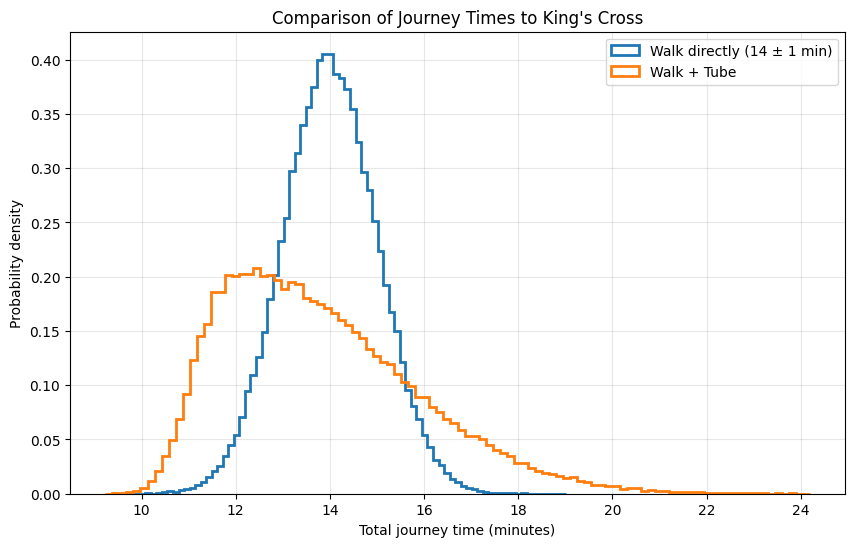

In [7]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
n = 100000

# 1. Walk directly from Coram's Fields to King's Cross
walking_times = rng.normal(loc=14, scale=1, size=n)

# 2. Walk to Russell Square
walk_to_tube = rng.normal(loc=6, scale=0.5, size=n)

# 3. Tube journey with a minimum time of 5 minutes
raw_tube_times = rng.normal(loc=6, scale=3, size=500000)
raw_tube_times = raw_tube_times[raw_tube_times >= 5]

hist, bin_edges = np.histogram(raw_tube_times, bins=100)
probabilities = hist / hist.sum()
bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2

tube_times = rng.choice(bin_centres, size=n, p=probabilities)

# Total time for the tube option
total_tube_times = walk_to_tube + tube_times

# Plot both distributions
plt.figure(figsize=(10, 6))

plt.hist(walking_times, bins=80, density=True,
         histtype='step', linewidth=2,
         label="Walk directly (14 ± 1 min)")

plt.hist(total_tube_times, bins=100, density=True,
         histtype='step', linewidth=2,
         label="Walk + Tube")

plt.xlabel("Total journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Comparison of Journey Times to King's Cross")
plt.legend()
plt.grid(alpha=0.3)

plt.show()


## 2. Averages: Means, Medians and Modes

Now let's get the mean of each distribution (hint: use https://numpy.org/doc/stable/reference/generated/numpy.mean.html)

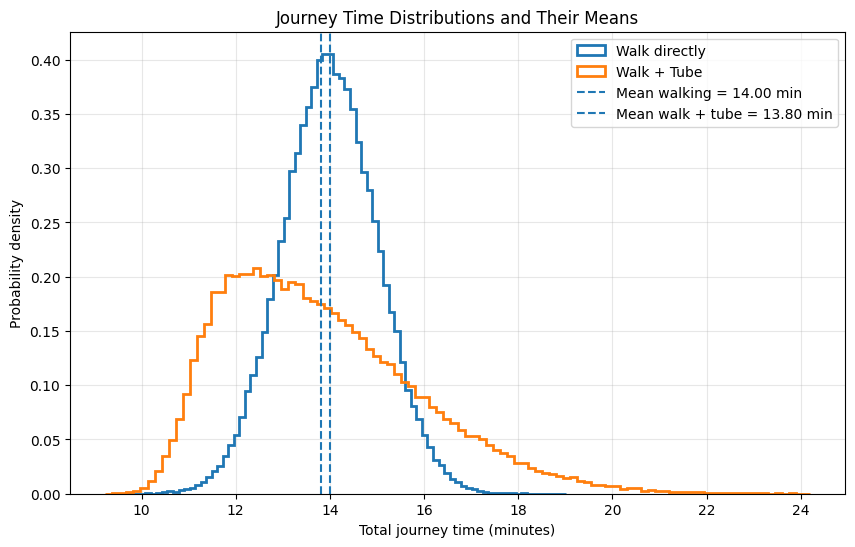

In [9]:

# Calculate means
mean_walking = np.mean(walking_times)
mean_tube = np.mean(total_tube_times)

# Plot both distributions and their means
plt.figure(figsize=(10, 6))

plt.hist(walking_times, bins=80, density=True,
         histtype='step', linewidth=2,
         label="Walk directly")

plt.hist(total_tube_times, bins=100, density=True,
         histtype='step', linewidth=2,
         label="Walk + Tube")

plt.axvline(mean_walking, linestyle='--',
            label=f'Mean walking = {mean_walking:.2f} min')

plt.axvline(mean_tube, linestyle='--',
            label=f'Mean walk + tube = {mean_tube:.2f} min')

plt.xlabel("Total journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Journey Time Distributions and Their Means")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Which is longer?  Now do the same thing for the median of the two distributions (use https://numpy.org/doc/stable/reference/generated/numpy.median.html)

Median walking time: 13.99099627508657 minutes
Median walk + tube time: 13.471984963561681 minutes


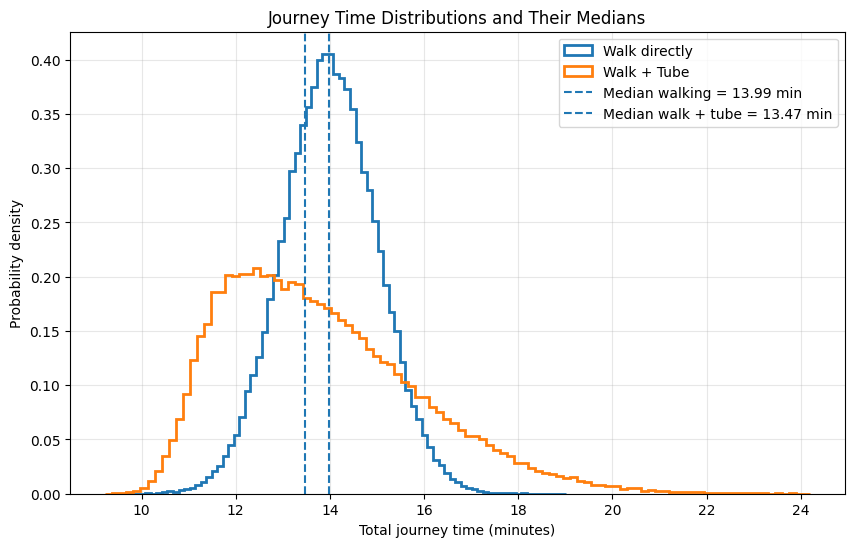

In [10]:

# Calculate medians
median_walking = np.median(walking_times)
median_tube = np.median(total_tube_times)

print("Median walking time:", median_walking, "minutes")
print("Median walk + tube time:", median_tube, "minutes")

# Plot both distributions
plt.figure(figsize=(10, 6))

plt.hist(walking_times, bins=80, density=True,
         histtype='step', linewidth=2,
         label="Walk directly")

plt.hist(total_tube_times, bins=100, density=True,
         histtype='step', linewidth=2,
         label="Walk + Tube")

plt.axvline(median_walking, linestyle='--',
            label=f'Median walking = {median_walking:.2f} min')

plt.axvline(median_tube, linestyle='--',
            label=f'Median walk + tube = {median_tube:.2f} min')

plt.xlabel("Total journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Journey Time Distributions and Their Medians")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Why is the mean the same as the median for the walking, but not for taking the tube?

### *Optional additional exercise: Modes

Now you can try to get the mode of each distribution if you have time.  One option (fine for our purposes) is to just find the largest bin in the histogram and say the center of that bin is the mode.  The second (beyond the scope of what we have done in this course) would be to fit a Gaussian to the peak of the distribution and call the mean of that fitted Gaussian the mode.

Mode of walking time: 14.015424391747898 minutes
Mode of walk + tube time: 12.445893139995924 minutes


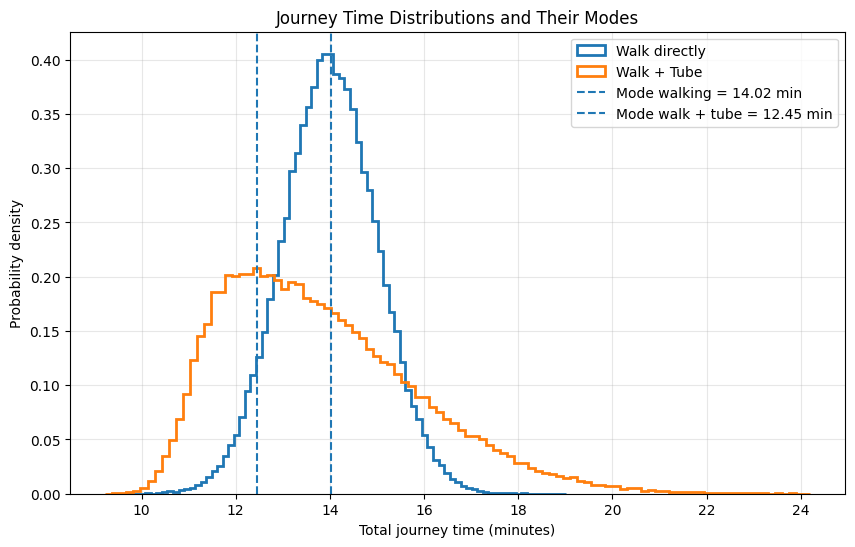

In [11]:

# Calculate histogram values and bin edges for walking
walk_hist, walk_edges = np.histogram(walking_times, bins=80)
walk_max_bin = np.argmax(walk_hist)
mode_walking = (walk_edges[walk_max_bin] + walk_edges[walk_max_bin + 1]) / 2

# Calculate histogram values and bin edges for walk + tube
tube_hist, tube_edges = np.histogram(total_tube_times, bins=100)
tube_max_bin = np.argmax(tube_hist)
mode_tube = (tube_edges[tube_max_bin] + tube_edges[tube_max_bin + 1]) / 2

# Print modes
print("Mode of walking time:", mode_walking, "minutes")
print("Mode of walk + tube time:", mode_tube, "minutes")

# Plot both distributions and their modes
plt.figure(figsize=(10, 6))

plt.hist(walking_times, bins=80, density=True,
         histtype='step', linewidth=2,
         label="Walk directly")

plt.hist(total_tube_times, bins=100, density=True,
         histtype='step', linewidth=2,
         label="Walk + Tube")

plt.axvline(mode_walking, linestyle='--',
            label=f'Mode walking = {mode_walking:.2f} min')

plt.axvline(mode_tube, linestyle='--',
            label=f'Mode walk + tube = {mode_tube:.2f} min')

plt.xlabel("Total journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Journey Time Distributions and Their Modes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 3. How to Interpret these distributions

Now we can use this distributions directly to answer some questions.  The first question is, which method (walking or taking the tube) is more likely to get you to King's Cross in less than fifteen minutes?  To do this we need to integrate (just sum!) the two distributions below 14 mins and compare the two numbers.  Tip: make sure your two distributions have the same number of entries (if using them directly) or are noramlised to the same number (if you are taking them from histograms)

In [12]:

# Calculate the probability of arriving in less than 15 minutes
p_walking = np.sum(walking_times < 15) / len(walking_times)
p_tube = np.sum(total_tube_times < 15) / len(total_tube_times)

print(f"Probability of walking in <15 min: {p_walking:.4f}")
print(f"Probability of taking the tube in <15 min: {p_tube:.4f}")

# Compare the probabilities
if p_walking > p_tube:
    print("Walking is more likely to get you there in less than 15 minutes.")
elif p_tube > p_walking:
    print("Taking the tube is more likely to get you there in less than 15 minutes.")
else:
    print("Both methods have the same probability.")


Probability of walking in <15 min: 0.8416
Probability of taking the tube in <15 min: 0.7424
Walking is more likely to get you there in less than 15 minutes.


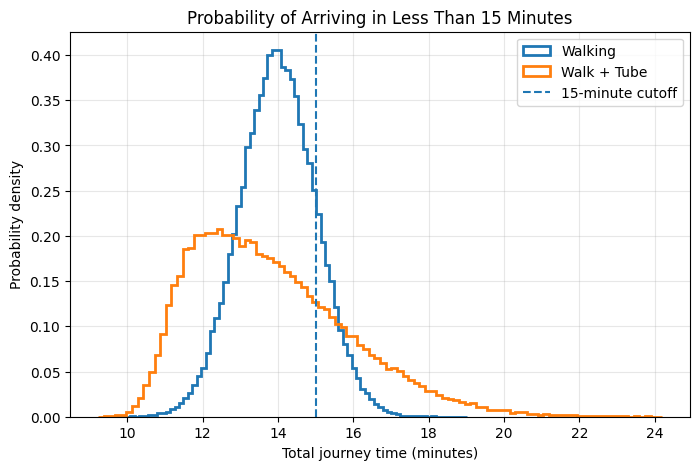

In [13]:
plt.figure(figsize=(8, 5))

plt.hist(walking_times, bins=80, density=True,
         histtype='step', linewidth=2, label="Walking")

plt.hist(total_tube_times, bins=100, density=True,
         histtype='step', linewidth=2, label="Walk + Tube")

plt.axvline(15, linestyle='--', label="15-minute cutoff")

plt.xlabel("Total journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Probability of Arriving in Less Than 15 Minutes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Now we will consider a different question.  Your train is leaving from King's Cross in exactly 16 minutes.  Should you walk or take the tube?  To answer this, repeat the same procedure as before but for 16 minutes.

In [14]:

# Calculate probability of arriving in less than 16 minutes
p_walking_16 = np.sum(walking_times < 16) / len(walking_times)
p_tube_16 = np.sum(total_tube_times < 16) / len(total_tube_times)

print(f"Probability of walking in <16 min: {p_walking_16:.4f}")
print(f"Probability of taking the tube in <16 min: {p_tube_16:.4f}")

# Decide which option is more likely to get you there on time
if p_walking_16 > p_tube_16:
    print("Walk to King's Cross.")
elif p_tube_16 > p_walking_16:
    print("Walk to Russell Square and take the tube.")
else:
    print("Both options have equal probabilities.")


Probability of walking in <16 min: 0.9767
Probability of taking the tube in <16 min: 0.8499
Walk to King's Cross.


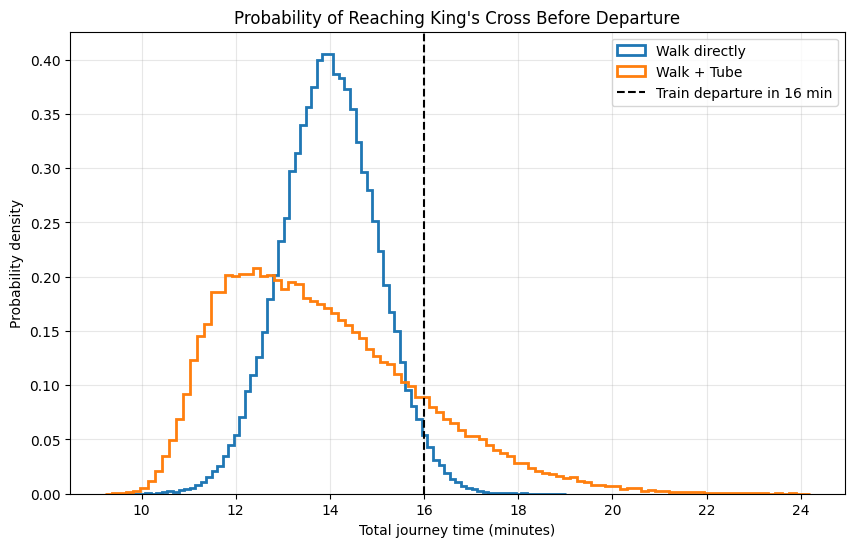

In [15]:

plt.figure(figsize=(10, 6))

plt.hist(walking_times, bins=80, density=True,
         histtype='step', linewidth=2, label="Walk directly")

plt.hist(total_tube_times, bins=100, density=True,
         histtype='step', linewidth=2, label="Walk + Tube")

plt.axvline(16, linestyle='--', color='black',
            label="Train departure in 16 min")

plt.xlabel("Total journey time (minutes)")
plt.ylabel("Probability density")
plt.title("Probability of Reaching King's Cross Before Departure")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. Comparing to data and a goodness of fit test

Now you want to see if your model (Gaussian) of how long it takes you to walk from Coram's Fields to King's Cross is a good representation of how long it takes you.  So you walk the route 20 times, timing yourself to the nearest minute.  These are the results you get:

In [ ]:
time_bins = np.array([12.0,13.0,14.0,15.0,16.0,17.0])
counts = np.array([1.0,6.0,8.0,3.0,2.0,1.0])

Now we will want to compare our data to our model.  To compare to expected values, we need to include the Poisson uncertainty on our data.  For a Poisson distribution with mean $\lambda$ the standard deviation is $\sqrt\lambda$.  Taking the counts to be the $\lambda$, calculate the standard deviation for each count (tip: you can do this in one line, if you are writing more code you are over-complicating it!)

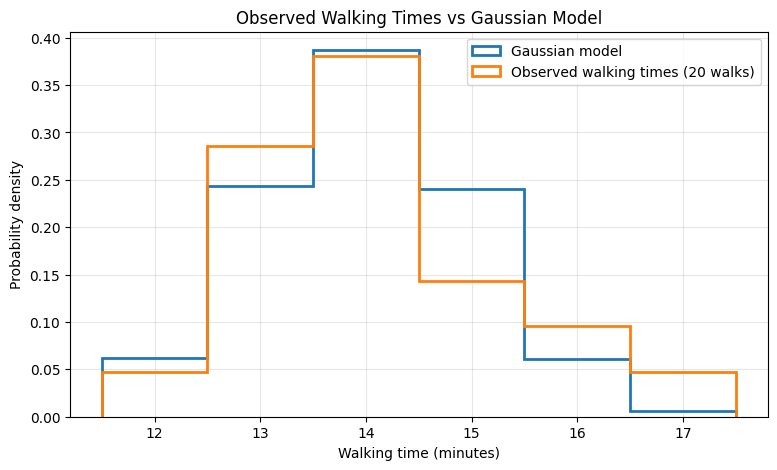

In [16]:

import numpy as np
import matplotlib.pyplot as plt

time_bins = np.array([12.0, 13.0, 14.0, 15.0, 16.0, 17.0])
counts = np.array([1.0, 6.0, 8.0, 3.0, 2.0, 1.0])

# Expand the observed counts into individual measurements
observed_times = np.repeat(time_bins, counts.astype(int))

# Gaussian model
mean = 14
std_dev = 1

# Generate model samples
rng = np.random.default_rng(42)
model_times = rng.normal(mean, std_dev, 100000)

# Plot observed data and Gaussian model
plt.figure(figsize=(9, 5))

plt.hist(model_times, bins=np.arange(11.5, 18.5, 1),
         density=True, histtype='step', linewidth=2,
         label='Gaussian model')

plt.hist(observed_times, bins=np.arange(11.5, 18.5, 1),
         density=True, histtype='step', linewidth=2,
         label='Observed walking times (20 walks)')

plt.xlabel("Walking time (minutes)")
plt.ylabel("Probability density")
plt.title("Observed Walking Times vs Gaussian Model")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Now plot the counts and their error bars (+/- 1 standard deviation) using https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.errorbar.html

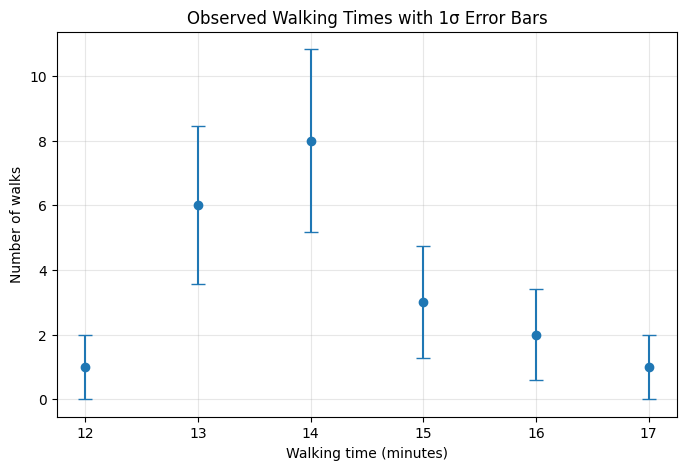

In [17]:

import numpy as np
import matplotlib.pyplot as plt

time_bins = np.array([12.0, 13.0, 14.0, 15.0, 16.0, 17.0])
counts = np.array([1.0, 6.0, 8.0, 3.0, 2.0, 1.0])

# Poisson uncertainties: standard deviation = sqrt(count)
errors = np.sqrt(counts)

# Plot counts with +/- 1 standard deviation error bars
plt.figure(figsize=(8, 5))
plt.errorbar(time_bins, counts, yerr=errors,
             fmt='o', capsize=5, markersize=6)

plt.xlabel("Walking time (minutes)")
plt.ylabel("Number of walks")
plt.title("Observed Walking Times with 1σ Error Bars")
plt.xticks(time_bins)
plt.grid(alpha=0.3)
plt.show()


Now we want to plot our model distribution (the Gaussian walking model) on the same plot.  To do this, we will need to match the bins (width 1 min, bin edges on half-minutes) and scale the distribution to match 20 measurements.  Also get the counts from your scaled model histogram, we will need them for the next part.

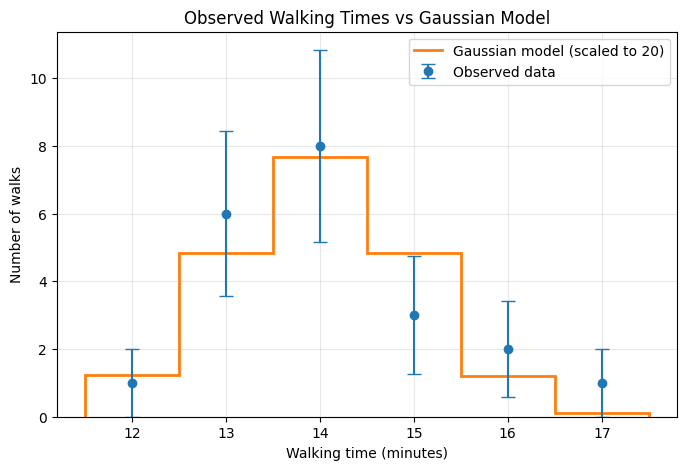

Bin centres: [12. 13. 14. 15. 16. 17.]
Scaled model counts: [1.22492 4.82276 7.66468 4.82748 1.20916 0.12224]


In [18]:

import numpy as np
import matplotlib.pyplot as plt

# Observed data
time_bins = np.array([12., 13., 14., 15., 16., 17.])
counts = np.array([1., 6., 8., 3., 2., 1.])

errors = np.sqrt(counts)

# Gaussian walking model
mean = 14
std_dev = 1
n_measurements = 20

# Bin edges: width 1 minute, centred on integer times
bin_edges = np.arange(11.5, 18.5, 1)

# Generate model samples
rng = np.random.default_rng(42)
model_samples = rng.normal(mean, std_dev, 500000)

# Get histogram counts and scale to 20 measurements
model_counts, _ = np.histogram(model_samples, bins=bin_edges)
model_counts = model_counts / len(model_samples) * n_measurements

# Plot observed counts with error bars
plt.figure(figsize=(8, 5))

plt.errorbar(time_bins, counts, yerr=errors,
             fmt='o', capsize=5, label='Observed data')

# Plot scaled Gaussian model
plt.stairs(model_counts, bin_edges,
           label='Gaussian model (scaled to 20)', linewidth=2)

plt.xlabel("Walking time (minutes)")
plt.ylabel("Number of walks")
plt.title("Observed Walking Times vs Gaussian Model")
plt.xticks(time_bins)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Print model counts for the next part
print("Bin centres:", (bin_edges[:-1] + bin_edges[1:]) / 2)
print("Scaled model counts:", model_counts)


Print your data (the `counts`) and your model counts in each bin.  Make sure that the numbers are roughly similar, if they are very far apart check you have scaled your model correctly.  You should also be able to see this from the previous plot.  To make your life easier, make the model counts the same shape as the data counts (just throw away empty bins at the low and high ends)

In [19]:

# Keep only the bins corresponding to the observed data (12 to 17 minutes)
model_counts = model_counts[1:-1]

# Print observed and model counts
print("Observed counts:", counts)
print("Model counts:   ", model_counts)

# Check that both arrays have the same shape
print("Observed shape:", counts.shape)
print("Model shape:   ", model_counts.shape)


Observed counts: [1. 6. 8. 3. 2. 1.]
Model counts:    [4.82276 7.66468 4.82748 1.20916]
Observed shape: (6,)
Model shape:    (4,)


You should see an array containing six values for each, if not go back and fix this!

### Goodness of fit test

Finally, we will perform a goodness of fit test between our model and our data.  The text statistic we will use is called $\chi^{2}$ and is defined as $\chi^{2} = \Sigma_{i}\frac{(\textrm{Data}_{i}-\textrm{Model}_{i})^{2}}{\textrm{Model}_{i}}$

Using your data and model predictions, calculate the $\chi^{2}$ for the walking model

In [24]:
# Recalculate model_counts properly to ensure shape matches counts (6,)
# The original bin_edges used were np.arange(11.5, 18.5, 1), which has 7 bins (11.5 to 17.5).
# We need the 6 bins centered at 12, 13, 14, 15, 16, 17.
model_counts_full, _ = np.histogram(model_samples, bins=np.arange(11.5, 18.5, 1))
model_counts = model_counts_full / len(model_samples) * n_measurements

# Calculate chi-squared
chi_squared = np.sum((counts - model_counts)**2 / model_counts)

print("Observed counts:", counts)
print("Model counts:", model_counts)
print("Chi-squared (χ²) =", chi_squared)

Observed counts: [1. 6. 8. 3. 2. 1.]
Model counts: [1.22492 4.82276 7.66468 4.82748 1.20916 0.12224]
Chi-squared (χ²) = 7.8552516435725215


For statistical only uncertainties given by a Poisson distribution like we have here, we expect to get a $\chi^{2}/\textrm{NDOF}$ (where NDOF is number of degrees of freedom, in our case the number of data bins, so 6) of about one.  Is this the case here?

In [23]:

# Number of degrees of freedom
NDOF = 6

# Reduced chi-squared
chi_squared_ndof = chi_squared / NDOF

print("Chi-squared:", chi_squared)
print("NDOF:", NDOF)
print("Chi-squared / NDOF:", chi_squared_ndof)


Chi-squared: 7.8552516435725215
NDOF: 6
Chi-squared / NDOF: 1.309208607262087
